In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


teh_041.png {'rerata': 173.4, 'simpangan_baku': 37.5, 'min': 67, 'maks': 238, 'persen_gelap': 0.0, 'persen_terang': 5.9}
teh_042.png {'rerata': 119.8, 'simpangan_baku': 38.3, 'min': 9, 'maks': 183, 'persen_gelap': 8.7, 'persen_terang': 0.0}
teh_043.png {'rerata': 211.4, 'simpangan_baku': 22.8, 'min': 146, 'maks': 244, 'persen_gelap': 0.0, 'persen_terang': 77.0}
teh_044.png {'rerata': 153.2, 'simpangan_baku': 13.7, 'min': 110, 'maks': 181, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png {'rerata': 120.5, 'simpangan_baku': 50.7, 'min': 28, 'maks': 239, 'persen_gelap': 1.3, 'persen_terang': 5.6}


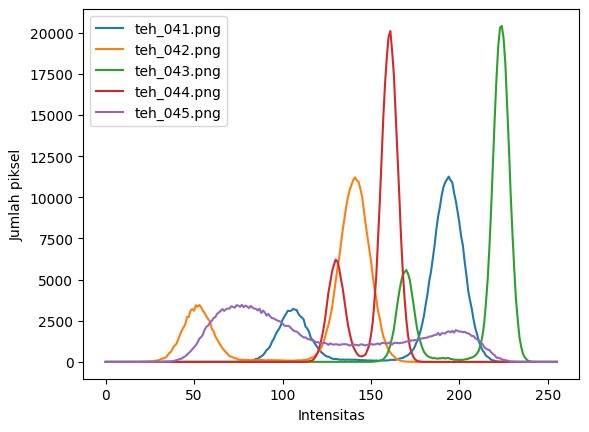

In [6]:
import sys
# Daftarkan folder src ke dalam sistem agar utils_cv terbaca
sys.path.append('/content/drive/MyDrive/simuteh-2330511092/src')

import cv2
import numpy as np
import matplotlib.pyplot as plt
from utils_cv import kontras_bercak, baca, statistik, tampil
for nama in ["teh_041.png", "teh_042.png", "teh_043.png",
 "teh_044.png", "teh_045.png"]:
 gray = cv2.cvtColor(baca(f"drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama}"),
 cv2.COLOR_BGR2GRAY)
 print(nama, statistik(gray))
 hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
 plt.plot(hist, label=nama)
plt.xlabel("Intensitas"); plt.ylabel("Jumlah piksel"); plt.legend()
plt.savefig("drive/MyDrive/simuteh-2330511092/hasil/b3_histogram_5kondisi.png")

In [7]:
nama = "teh_045.png" # kondisi bayangan
img = baca(f"drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama}")
md = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
def gamma_lut(g):
 lut = np.array([255 * (i / 255) ** g for i in range(256)])
 return lut.clip(0, 255).astype(np.uint8)
rmin, rmax = np.percentile(gray, (2, 98)) # abaikan 2% piksel ekstrem
hasil = {
 "asli": gray,
 "negatif": 255 - gray,
 "cerah+50": cv2.add(gray, 50),
 "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
 "regang": np.clip((gray - rmin) / (rmax - rmin) * 255,
 0, 255).astype(np.uint8),
 "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
 "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
 "ekualisasi": cv2.equalizeHist(gray),
 "CLAHE": cv2.createCLAHE(clipLimit=2.0,
 tileGridSize=(8, 8)).apply(gray),
}
for nm, c in hasil.items():
 print(f"{nm:10s} KB={kontras_bercak(c, md, mb):.2f} "
 f"sigma={c.std():.1f}")

asli       KB=1.55 sigma=50.7
negatif    KB=1.55 sigma=50.7
cerah+50   KB=1.55 sigma=50.0
kontras    KB=1.55 sigma=73.2
regang     KB=1.58 sigma=79.8
gamma0.5   KB=1.35 sigma=36.6
gamma1.8   KB=1.91 sigma=53.9
ekualisasi KB=1.10 sigma=73.4
CLAHE      KB=1.87 sigma=44.3


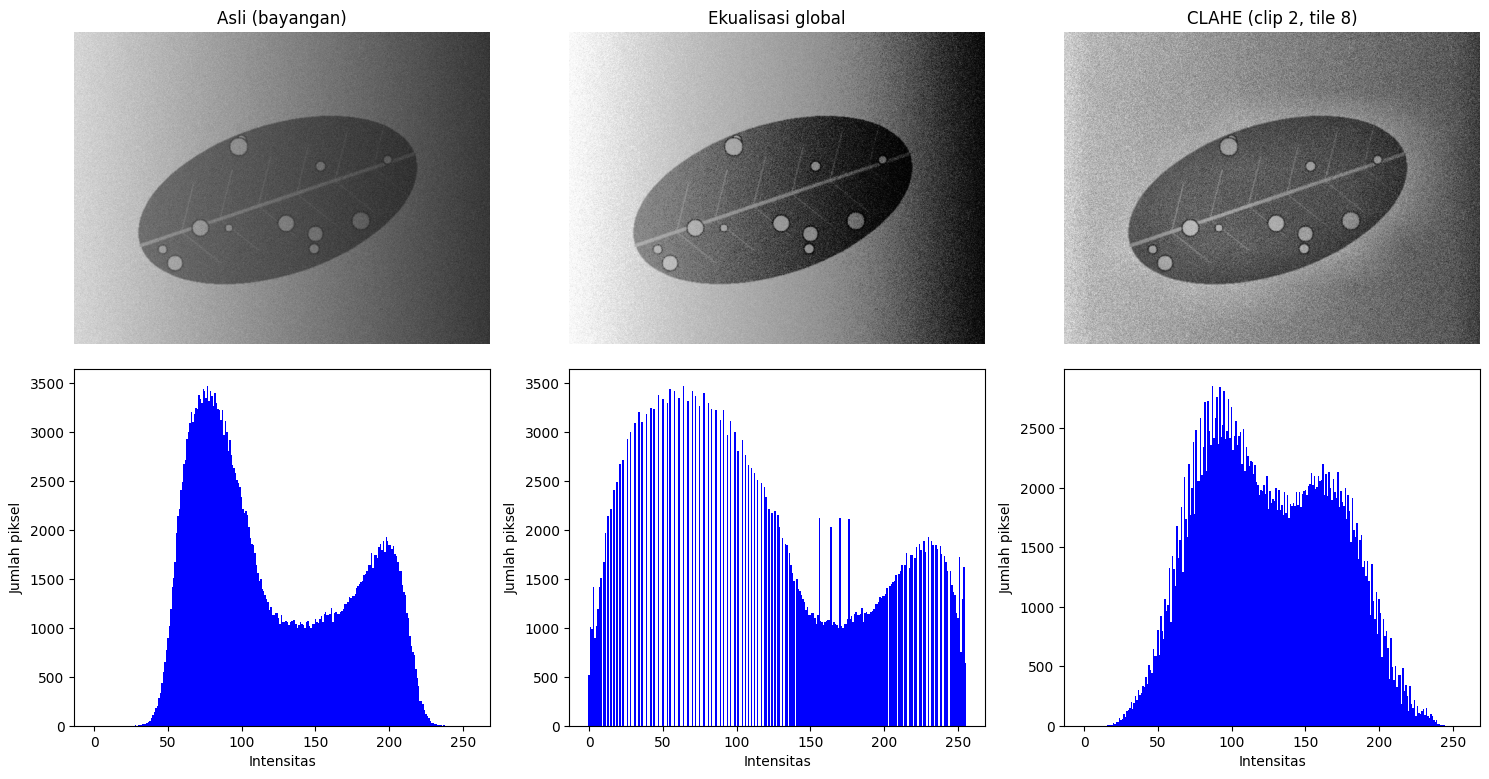

In [9]:
# Pilih 3 citra yang akan divisualisasikan sesuai Gambar 4[cite: 16]
citra_pilihan = [hasil["asli"], hasil["ekualisasi"], hasil["CLAHE"]]
judul_pilihan = ["Asli (bayangan)", "Ekualisasi global", "CLAHE (clip 2, tile 8)"]

plt.figure(figsize=(15, 8))
for i, (c, judul) in enumerate(zip(citra_pilihan, judul_pilihan)):
    # Baris atas: Citra
    plt.subplot(2, 3, i + 1)
    plt.imshow(c, cmap='gray', vmin=0, vmax=255)
    plt.title(judul)
    plt.axis('off')

    # Baris bawah: Histogram
    plt.subplot(2, 3, i + 4)
    hist = cv2.calcHist([c], [0], None, [256], [0, 256])
    plt.bar(range(256), hist.flatten(), color='blue', width=1)
    plt.xlabel("Intensitas")
    plt.ylabel("Jumlah piksel")

plt.tight_layout()
plt.show()

clip=1.0 tile=4: KB=2.07
clip=1.0 tile=8: KB=2.04
clip=1.0 tile=16: KB=2.02
clip=2.0 tile=4: KB=2.05
clip=2.0 tile=8: KB=1.87
clip=2.0 tile=16: KB=1.79
clip=4.0 tile=4: KB=1.74
clip=4.0 tile=8: KB=1.47
clip=4.0 tile=16: KB=1.41


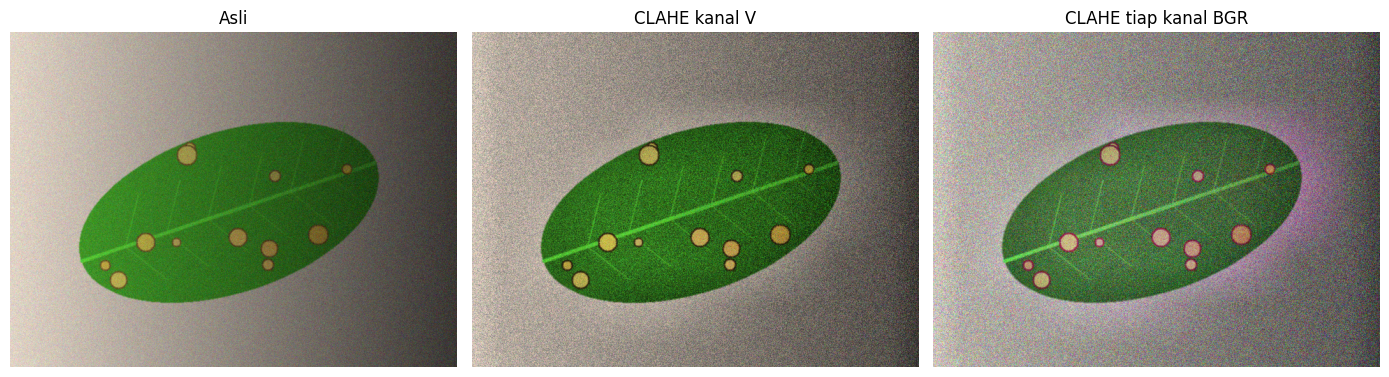

In [8]:
# eksperimen parameter CLAHE
for clip in [1.0, 2.0, 4.0]:
    for tile in [4, 8, 16]:
        c = cv2.createCLAHE(clipLimit=clip, tileGridSize=(tile, tile)).apply(gray)
        print(f"clip={clip} tile={tile}: KB={kontras_bercak(c, md, mb):.2f}")

# CLAHE pada citra warna: kanal V (benar) dan tiap kanal BGR (bandingkan)
clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
via_v = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)
via_bgr = cv2.merge([clahe.apply(c) for c in cv2.split(img)])
tampil([img, via_v, via_bgr], ["Asli", "CLAHE kanal V", "CLAHE tiap kanal BGR"])

Penerapan CLAHE pada kanal V (HSV) mempertahankan keaslian warna objek karena hanya meningkatkan kontras pencahayaan, sedangkan CLAHE pada tiap kanal BGR terpisah dapat menimbulkan distorsi warna yang tidak natural.

In [10]:
def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

pasangan_uji = [
    ("Kondisi Gelap", "teh_042.png", "teh_022.png", lambda g: cv2.LUT(g, gamma_lut(0.5))),
    ("Kondisi Terang", "teh_043.png", "teh_023.png", lambda g: cv2.LUT(g, gamma_lut(1.8))),
    ("Kondisi Kontras Rendah", "teh_044.png", "teh_024.png", lambda g: cv2.convertScaleAbs(g, alpha=1.5, beta=-40)),
    ("Kondisi Bayangan", "teh_045.png", "teh_025.png", lambda g: cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8)).apply(g))
]

for deskripsi, nama_berat, nama_ringan, metode in pasangan_uji:
    print(f"\n=== {deskripsi} ===")
    for nama in [nama_berat, nama_ringan]:
        path = f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/citra/{nama}"
        im_bgr = baca(path)
        m_d = cv2.imread(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/mask_daun/{nama}", 0)
        m_b = cv2.imread(f"/content/drive/MyDrive/simuteh-2330511092/data/sintetis/mask_bercak/{nama}", 0)

        g = cv2.cvtColor(im_bgr, cv2.COLOR_BGR2GRAY)
        g_hasil = metode(g)

        kb_awal = kontras_bercak(g, m_d, m_b)
        kb_akhir = kontras_bercak(g_hasil, m_d, m_b)
        print(f"File: {nama} | KB Awal: {kb_awal:.2f} -> KB Sesudah Perbaikan: {kb_akhir:.2f}")


=== Kondisi Gelap ===
File: teh_042.png | KB Awal: 3.97 -> KB Sesudah Perbaikan: 3.21
File: teh_022.png | KB Awal: 2.70 -> KB Sesudah Perbaikan: 2.05

=== Kondisi Terang ===
File: teh_043.png | KB Awal: 4.31 -> KB Sesudah Perbaikan: 4.62
File: teh_023.png | KB Awal: 1.34 -> KB Sesudah Perbaikan: 1.48

=== Kondisi Kontras Rendah ===
File: teh_044.png | KB Awal: 3.10 -> KB Sesudah Perbaikan: 3.10
File: teh_024.png | KB Awal: 1.10 -> KB Sesudah Perbaikan: 1.10

=== Kondisi Bayangan ===
File: teh_045.png | KB Awal: 1.55 -> KB Sesudah Perbaikan: 1.87
File: teh_025.png | KB Awal: 1.17 -> KB Sesudah Perbaikan: 2.13


In [11]:
%cd /content/drive/MyDrive/simuteh-2330511092

/content/drive/MyDrive/simuteh-2330511092


In [12]:
!git config --global user.email "gentaaditya18@gmail.com"
!git config --global user.name "Adityagenta"

In [ ]:
!git add .